# Logistic Regression với TensorFlow — Phân loại xe (Vehicle Classification)

Notebook cài đặt mô hình **Binary Logistic Regression** bằng TensorFlow (compatibility v1) cho bài toán phân loại xe. Notebook được chia thành các khối theo thứ tự chạy: **import**, **nạp & tiền xử lý dữ liệu**, **các TODO xây dựng đồ thị TensorFlow**, **thiết lập huấn luyện** và **training loop**.

> Chạy các cell theo thứ tự từ trên xuống dưới. Các module `util.py` và `logistic_np.py` cần có thể được import từ môi trường hiện tại, và file `vehicles.dat` cần nằm trong thư mục `data/`.

## 1. Import thư viện và các module

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow.compat.v1 as tf
from util import get_vehicle_data
from logistic_np import *

tf.compat.v1.disable_eager_execution()

I0000 00:00:1791987091.823079   72128 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


## 2. Nạp dữ liệu và tiền xử lý

In [3]:
np.random.seed(2018)
tf.set_random_seed(2018)

# Load data from file
# Make sure that vehicles.dat is in data/
train_x, train_y, test_x, test_y = get_vehicle_data()
num_train = train_x.shape[0]
num_test = test_x.shape[0]

# Normalize our data: choose one of the two methods before training
# train_x, test_x = normalize_all_pixel(train_x, test_x)
train_x, test_x = normalize_per_pixel(train_x, test_x)

# Reshape our data
# train_x: shape=(2400, 64, 64) -> shape=(2400, 64*64)
# test_x: shape=(600, 64, 64) -> shape=(600, 64*64)
train_x = reshape2D(train_x)
test_x = reshape2D(test_x)

# Pad 1 as the last feature of train_x and test_x
train_x = add_one(train_x)
test_x = add_one(test_x)

Reading vehicle data...
EOF Reached
Done reading


## 3. TODO 1.11 và TODO 1.12

- **TODO 1.11:** Tạo các TF constant chứa `train_x`, `train_y` và `test_x` để đưa vào đồ thị - tạo constant thay cho placeholder để quá trình train diễn ra nhanh hơn, do constant nạp trực tiếp dữ liệu vào VRAM GPU, còn placeholder cần chờ feed
- **TODO 1.12:** Tạo trọng số `w` (shape `(4097, 1)`) bằng `tf.Variable`, khởi tạo theo phân phối chuẩn với `stddev=0.01`.

In [4]:
# [TODO 1.11] Create TF placeholders / constants to feed train_x and train_y when training
train_x_tf = tf.constant(train_x, dtype=tf.float32, name="image_pixel")
train_y_tf = tf.constant(train_y, dtype=tf.float32, name="classifier_out")
test_x_tf = tf.constant(test_x, dtype=tf.float32, name="test_pixel")

# [TODO 1.12] Create weights (W) using TF variables
w = tf.Variable(tf.random.normal(shape=(4097, 1), stddev=0.01), name="w")

## 4. TODO 1.13 và TODO 1.14

- **TODO 1.13:** Tính `logits = X·w`, áp dụng sigmoid để ra xác suất, và tạo nhãn dự đoán trên tập test với ngưỡng 0.5.
- **TODO 1.14:** Binary cross-entropy trung bình trên tập train; xác suất được `clip` vào `[1e-7, 1 - 1e-7]` để tránh `log(0)`.

In [5]:
logits = tf.matmul(train_x_tf, w)
logits_test = tf.matmul(test_x_tf, w)

# [TODO 1.13] Create a feed-forward operator
z = tf.nn.sigmoid(logits, name="target_function")
z_test = tf.nn.sigmoid(logits_test, name="target_function_test")
pred_test = tf.cast(tf.greater(z_test, 0.5), tf.float32)

# [TODO 1.14] Write the cost function
z_clipped = tf.clip_by_value(z, 1e-7, 1 - 1e-7)
cost = -tf.reduce_sum(
    train_y_tf * tf.math.log(z_clipped) + (1 - train_y_tf) * tf.math.log(1 - z_clipped)
) / num_train

## 5. TODO 1.15

Khai báo các tham số  cho quá trình huấn luyện và tạo optimizer SGD (`GradientDescentOptimizer`) để  tối thiếu hóa `cost`. Biến `momentum_rate` được khai báo sẵn tuy nhiên dùng optimizer là SGD thuần - không dùng momentum, do train khá nhanh, momentum dùng khi train các tập dữ liệu lớn và mạng neural nhiều lớp, bài này không cần.

In [6]:
# Define hyper-parameters and train-related parameters
num_epoch = 300
learning_rate = 0.03
momentum_rate = 0.9

# [TODO 1.15] Create an SGD optimizer
optimizer = tf.train.GradientDescentOptimizer(learning_rate=learning_rate)
train_op = optimizer.minimize(cost)

# Some meta parameters
epochs_to_draw = 100
all_loss = []
plt.ion()

## 6. TODO 1.16

Khởi tạo biến và mở `tf.Session`. Mỗi epoch chạy `train_op` để cập nhật trọng số đồng thời lấy giá trị `cost`; cứ mỗi `epochs_to_draw` epoch thì vẽ đường loss và in ra. Sau khi huấn luyện xong, dự đoán nhãn trên tập test ngay trong session.

I0000 00:00:1791987134.090805   72128 gpu_device.cc:2036] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 2611 MB memory:  -> device: 0, name: Quadro T1000, pci bus id: 0000:01:00.0, compute capability: 7.5
I0000 00:00:1791987134.189701   72128 mlir_graph_optimization_pass.cc:437] MLIR V1 optimization pass is not enabled


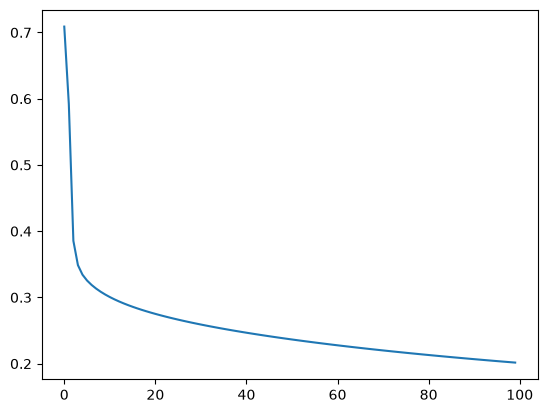

Epoch 100: loss is 0.20159


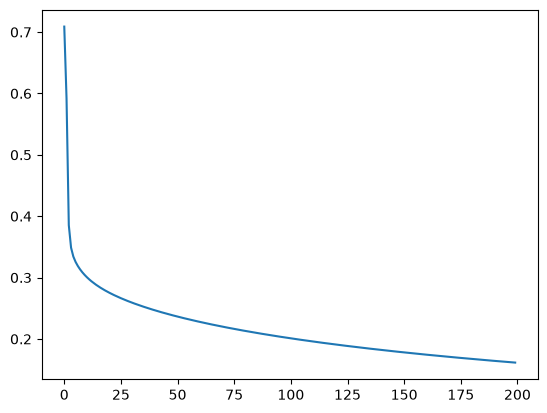

Epoch 200: loss is 0.16154


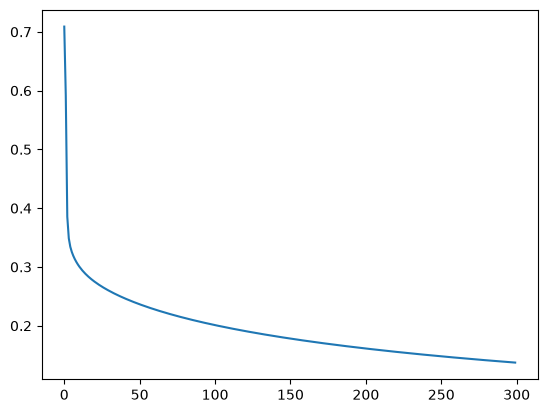

Epoch 300: loss is 0.13730


In [7]:
init = tf.global_variables_initializer()

with tf.Session() as sess:
    sess.run(init)

    for e in range(num_epoch):
        # [TODO 1.16] Compute loss and update weights here
        _, loss = sess.run([train_op, cost])
        all_loss.append(loss)

        if (e % epochs_to_draw == epochs_to_draw - 1):
            plot_loss(all_loss)
            plt.show()
            plt.pause(0.1)
            print("Epoch %d: loss is %.5f" % (e + 1, loss))

    # Predict on the test set while the session is still open
    y_hat = sess.run(pred_test)

## 7. Đánh giá trên tập test

Dùng hàm `test` (từ `logistic_np`) để so sánh nhãn dự đoán `y_hat` với nhãn thực tế `test_y`.

In [8]:
test(y_hat, test_y)

Precision: 0.762
Recall: 0.820
F1-score: 0.790


(np.float64(0.7616099071207431),
 np.float64(0.82),
 np.float64(0.7897271268057784))